In [1]:
%load_ext rpy2.ipython

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.


In [3]:
%%R
dir.exists("D:/clipped_mseed")

[1] TRUE


Error in (function (expr, envir = parent.frame(), enclos = if (is.list(envir) ||  : 
  object 's' not found


RInterpreterError: Failed to parse and evaluate line '# Check the two original seismic records\n\nfor (nm in names(s)) {\n\n  cat("\\n-------------------------\\n")\n  cat("Sensor:", nm, "\\n")\n\n  cat("Class:", class(s[[nm]])[1], "\\n")\n\n  cat("Sampling interval (dt):",\n      s[[nm]]$meta$dt, "\\n")\n\n  cat("Sampling rate:",\n      1 / s[[nm]]$meta$dt, "\\n")\n\n  cat("Number of samples:",\n      s[[nm]]$meta$n, "\\n")\n\n  cat("Start time:",\n      as.character(s[[nm]]$meta$starttime), "\\n")\n\n  cat("End time:",\n      as.character(\n        s[[nm]]$meta$starttime +\n          (s[[nm]]$meta$n - 1) * s[[nm]]$meta$dt\n      ), "\\n")\n\n  cat("Signal length:",\n      length(s[[nm]]$signal), "\\n")\n\n  cat("Missing signal values:",\n      sum(is.na(s[[nm]]$signal)), "\\n")\n}\n\n\n# Compare requested clipping windows with record times\n\nfor (i in seq_len(nrow(blows))) {\n\n  requested_start <- blows$start[i]\n  requested_end <- blows$start[i] + blows$duration[i]\n\n  cat("\\nSe

In [5]:
%%R
library(eseis)
setwd(file.path("D:", "clipped_mseed"))

# config

# sampling rate
fs <- 1000
dt <- 1 / fs

# frequency centers (Hz)
f <- c(5, 10, 15, 20, 25, 30, 35, 40)

# load seismic records
# a = Node 1
# b = Node 2

s <- list(
  a = read_mseed(file = "ZE.2511..GPZ_20251023214451_clipped.mseed"),
  b = read_mseed(file = "ZE.C2511..GPZ_20251023215340_clipped.mseed")
)

# transect geometry

# total transect length (meters)
L <- 44.2

# position of each hammer-strike SET, measured from og node (verify direction)
#source_x <- c(43, 41, 39, 37, 35, 33, 31, 29, 27, 25, 24, 22, 20, 18, 16.1, 14, 12, 10, 8.1, 6)
source_x <- c(35, 33, 31, 29)

# distance from each strike position to each node
source_dist_N1 <- source_x
source_dist_N2 <- L - source_x

# difference in strike-to-node distances
# this is the path-length difference used for the simple apparent velocity calculation
delta_r <- source_dist_N2 - source_dist_N1

geometry <- data.frame(
  set = seq_along(source_x),
  x_m = source_x,
  dist_N1_m = source_dist_N1,
  dist_N2_m = source_dist_N2,
  delta_r_m = delta_r
)

print(geometry)

# approx hammer strike windows

# each row represents ONE source location / SET of five hammer strikes

# start = approximate beginning of the five-strike set
# duration = approximate length of the set

# these are NOT individual P-wave arrival times
# STA/LTA and kurtosis will help identify the individual events inside each window

# this will need editing when using full/longer miniseed files
blows <- data.frame(
  set = 1:4,

  start = as.POSIXct(
    c(
      "2025-10-23 22:03:16",
      "2025-10-23 22:04:37",
      "2025-10-23 22:05:42",
      "2025-10-23 22:06:42"
    ),
    tz = "UTC"
  ),

  duration = c(35, 20, 20, 22)
)

# add source position information
blows <- merge(
  blows,
  geometry,
  by = "set",
  sort = TRUE
)

print(blows)


# picker params

# STA/LTA parameters
sta <- 200
lta <- 4000

stalta_on <- 5
stalta_off <- 3

# kurtosis parameters
# these are inital test values, not validated settings
# tune by inspecting the resulting picks

kurt_window <- 200
kurt_amp_window <- 300

kurt_dur_min <- 0.01
kurt_dur_max <- 2


kurt_on <- 15
kurt_off <- 5

# kurt_dur_min <- 10
# kurt_dur_max <- 2000

# cross-correlation maximum lag (samples)
# 1000 samples = 1 second at 1000 Hz.
lag_max <- 1000

# additional time window around each detected event - buffer
pre_buffer <- 0.2
post_buffer <- 0.4

# plot controls
show_individual_plots <- TRUE


  set x_m dist_N1_m dist_N2_m delta_r_m
1   1  35        35       9.2     -25.8
2   2  33        33      11.2     -21.8
3   3  31        31      13.2     -17.8
4   4  29        29      15.2     -13.8
  set               start duration x_m dist_N1_m dist_N2_m delta_r_m
1   1 2025-10-23 22:03:16       35  35        35       9.2     -25.8
2   2 2025-10-23 22:04:37       20  33        33      11.2     -21.8
3   3 2025-10-23 22:05:42       20  31        31      13.2     -17.8
4   4 2025-10-23 22:06:42       22  29        29      15.2     -13.8



Processing set: 1 

Processing set: 2 

Processing set: 3 

Processing set: 4 


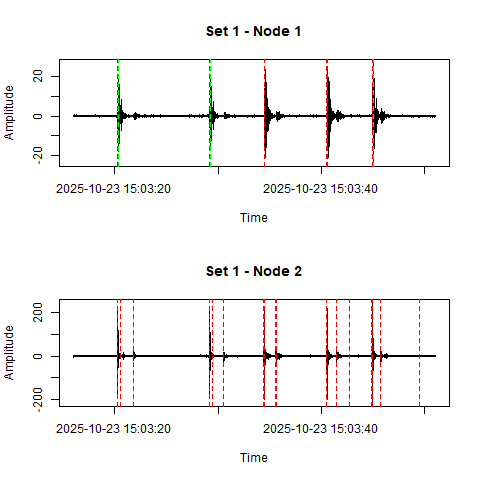

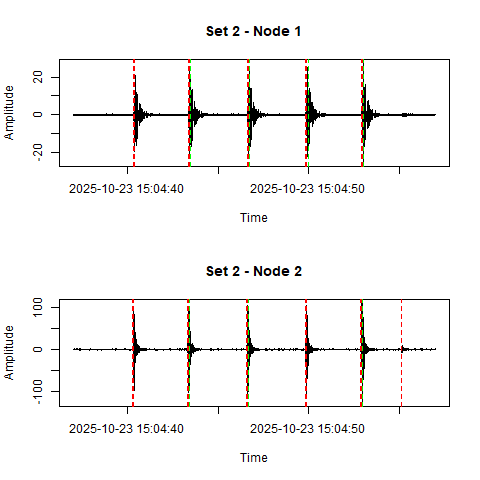

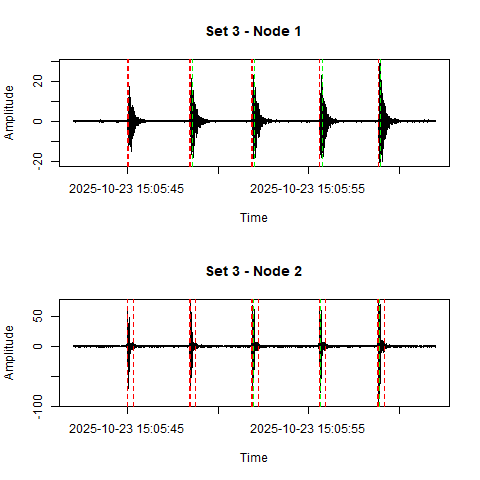

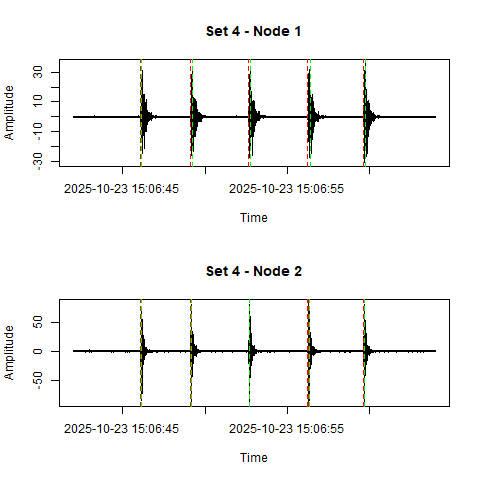

In [6]:
%%R
# output object
results <- list()

# process each set of 5 strikes
for (i in seq_len(nrow(blows))) {

  cat("\nProcessing set:", i, "\n")

  # extract this experiment window
  s_blow <- signal_clip(
    data = s,
    limits = c(
      blows$start[i],
      blows$start[i] + blows$duration[i]
    )
  )

  # STA/LTA picking

  e_blow <- signal_envelope(data = s_blow)

  p_stalta <- pick_stalta(
    data = e_blow,
    sta = sta,
    lta = lta,
    freeze = TRUE,
    on = stalta_on,
    off = stalta_off
  )

  # kurtosis picking

  p_kurt <- pick_kurtosis(
    data = e_blow,
    window_kurt = kurt_window,
    on = kurt_on,
    off = kurt_off,
    dur_min = kurt_dur_min,
    dur_max = kurt_dur_max,
    window_amp = kurt_amp_window
  )

  # retain both sets of picks - do not assume they identify identical events
  picks_stalta_A <- p_stalta$a$picks
  picks_stalta_B <- p_stalta$b$picks

  picks_kurt_A <- p_kurt$a$picks
  picks_kurt_B <- p_kurt$b$picks

  # plot original data and detected events
  if (show_individual_plots) {

    par(mfrow = c(2, 1))

    plot(
      s_blow$a,
      main = paste("Set", i, "- Node 1")
    )

    abline(
      v = picks_stalta_A$start,
      col = "green",
      lty = 2
    )

    abline(
      v = picks_kurt_A$start,
      col = "red",
      lty = 2
    )

    plot(
      s_blow$b,
      main = paste("Set", i, "- Node 2")
    )

    abline(
      v = picks_stalta_B$start,
      col = "green",
      lty = 2
    )

    abline(
      v = picks_kurt_B$start,
      col = "red",
      lty = 2
    )

    par(mfrow = c(1, 1))
  }


  # save results for this strike set

  results[[i]] <- list(
    source = blows[i, ],
    waveform = s_blow,
    envelope = e_blow,
    stalta_A = picks_stalta_A,
    stalta_B = picks_stalta_B,
    kurtosis_A = picks_kurt_A,
    kurtosis_B = picks_kurt_B
  )
}



-------------------------------------
Processing set: 1 
Source position: 43 m from Node 1

-------------------------------------

Frequency: 5 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 3 
Node 2 kurtosis: 10 

Frequency: 10 Hz
Node 1 STA/LTA: 3 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 1 
Node 2 kurtosis: 4 

Frequency: 15 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 1 
Node 2 kurtosis: 6 

Frequency: 20 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 0 
Node 2 kurtosis: 6 

Frequency: 25 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 2 
Node 2 kurtosis: 8 

Frequency: 30 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 1 
Node 2 kurtosis: 9 

Frequency: 35 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 0 
Node 2 kurtosis: 11 

Frequency: 40 Hz
Node 1 STA/LTA: 5 
Node 2 STA/LTA: 5 
Node 1 kurtosis: 1 
Node 2 kurtosis: 7 

-------------------------------------
Processing set: 2 
Source position: 41 m from Node 1

-------

Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed
Kurtosis failed for Node 1: missing value where TRUE/FALSE needed


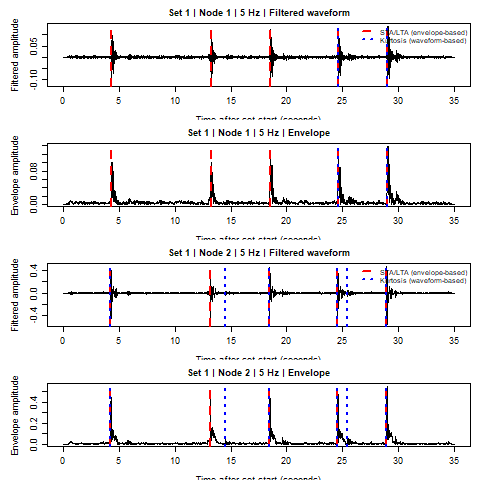

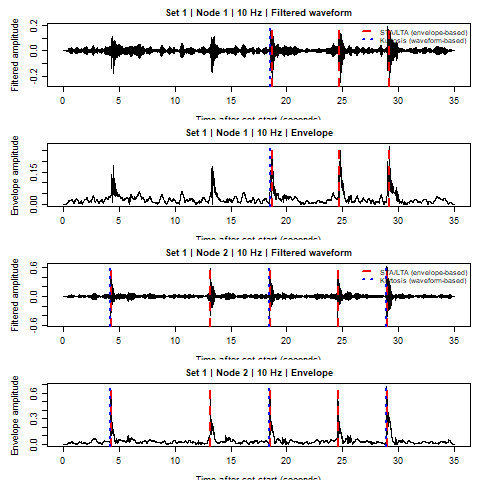

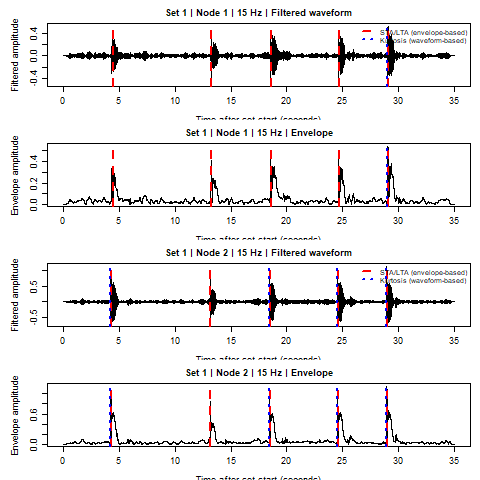

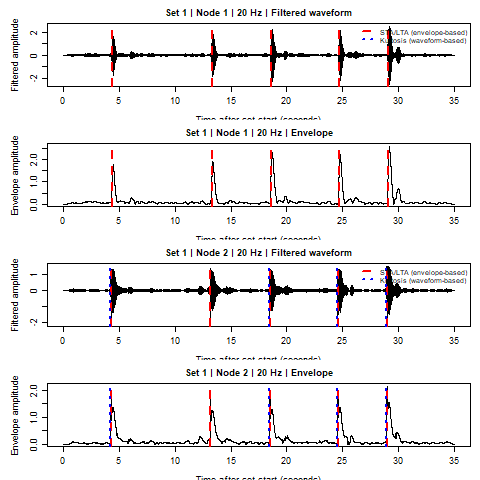

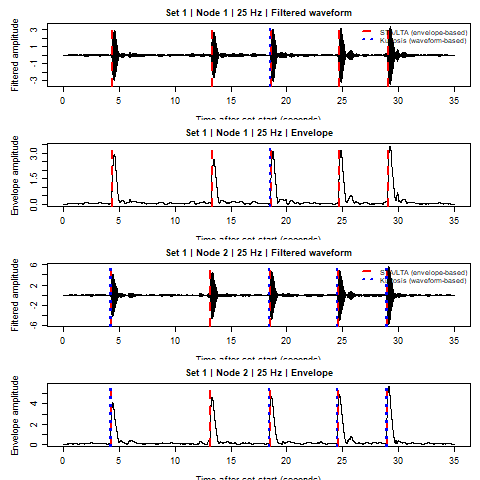

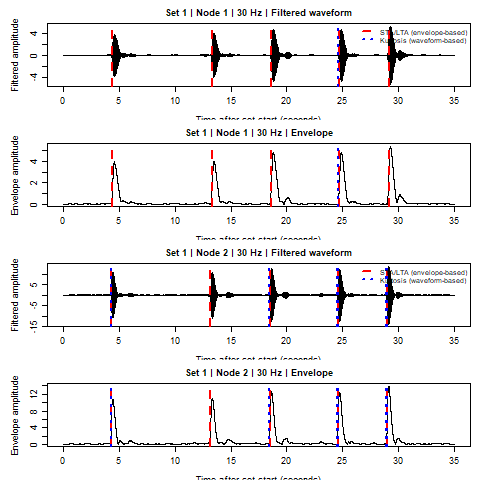

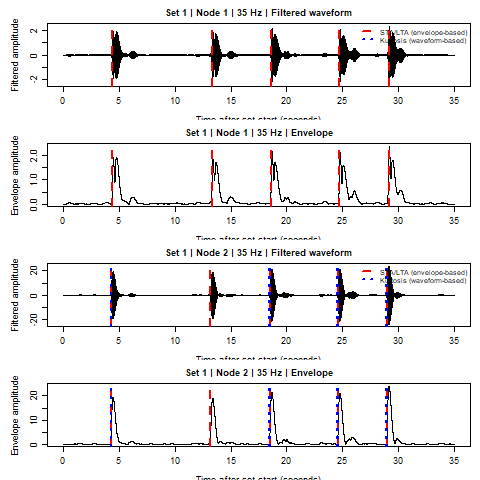

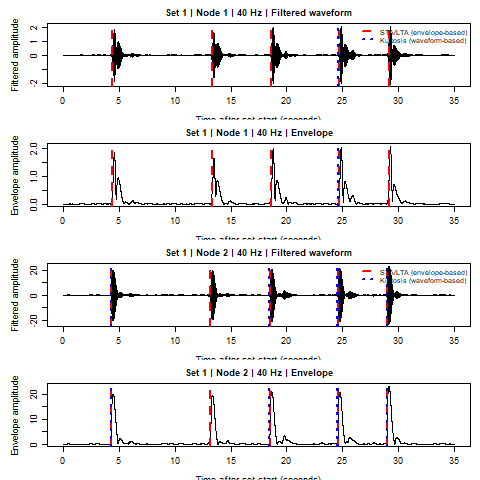

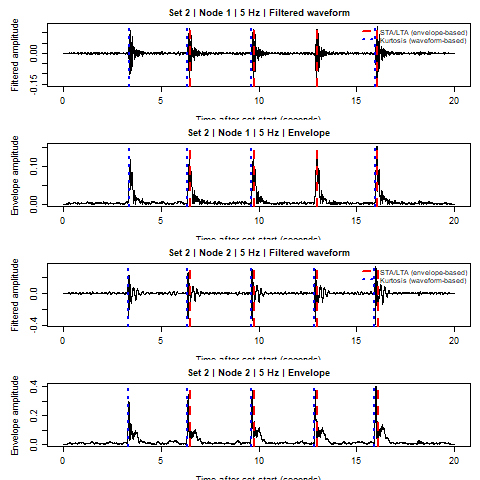

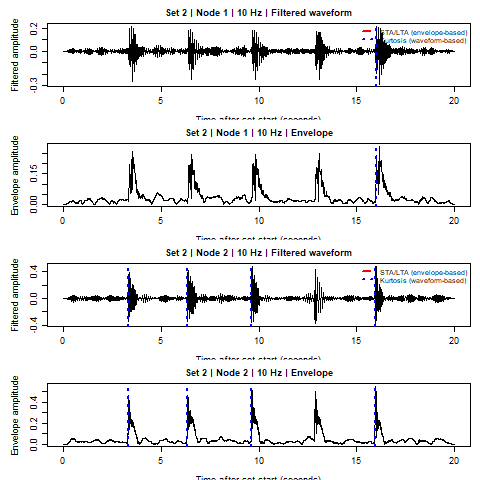

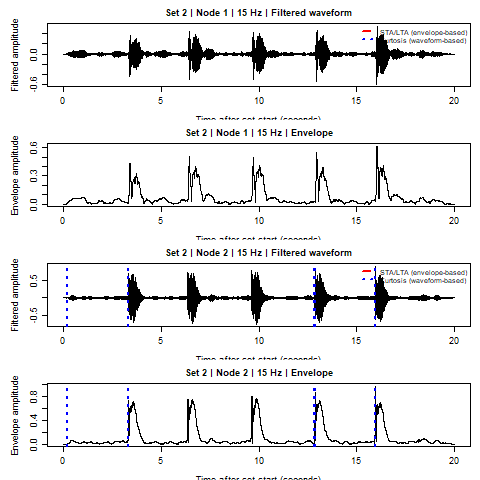

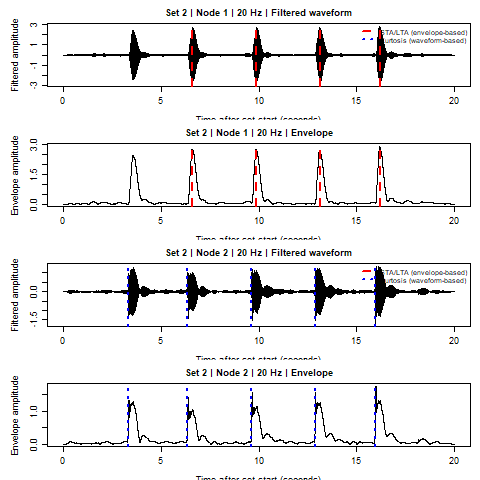

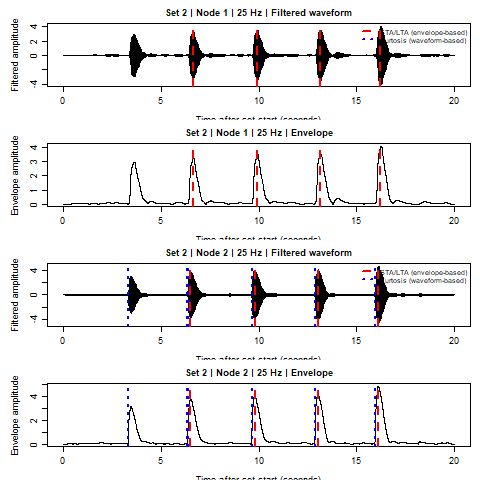

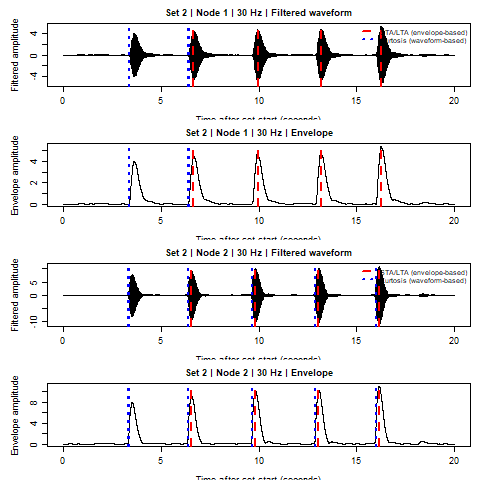

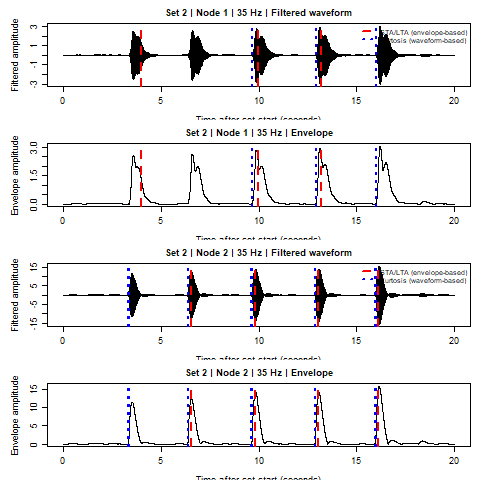

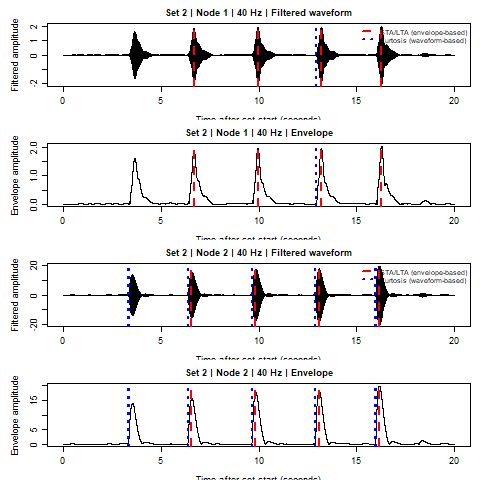

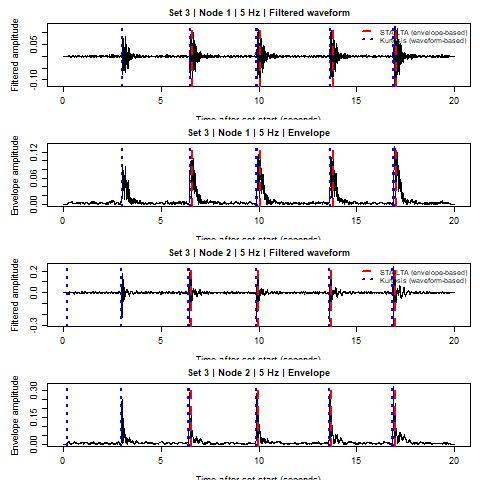

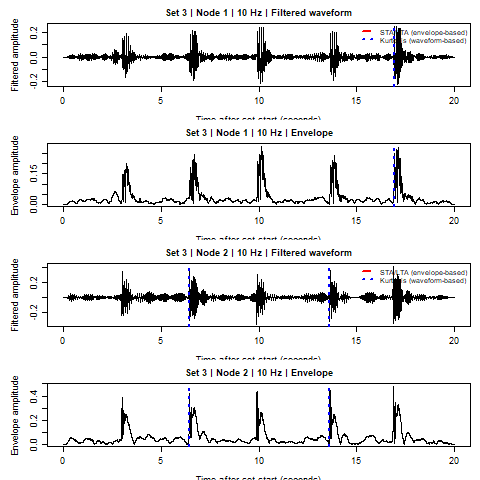

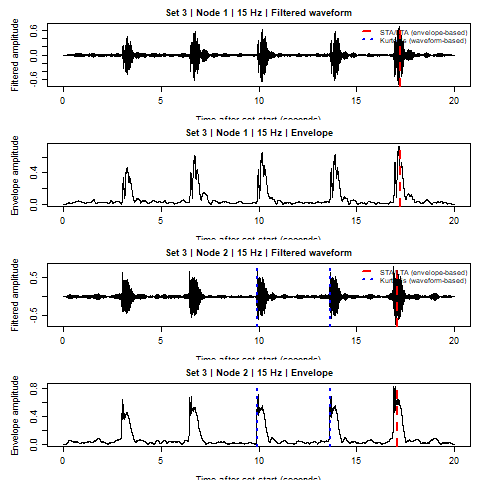

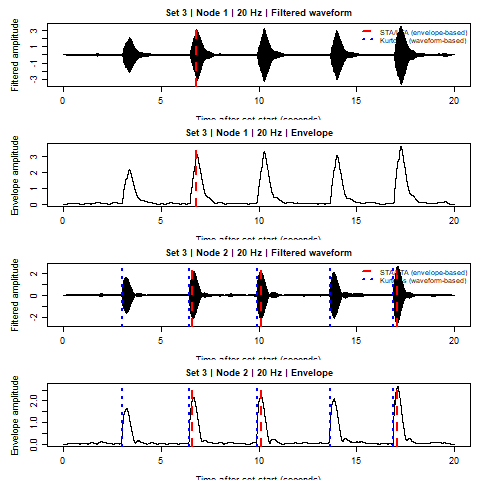

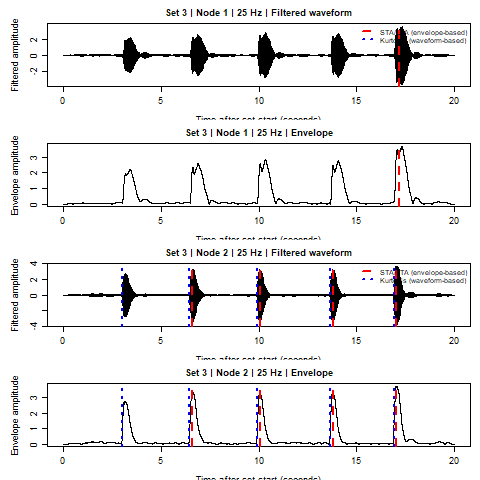

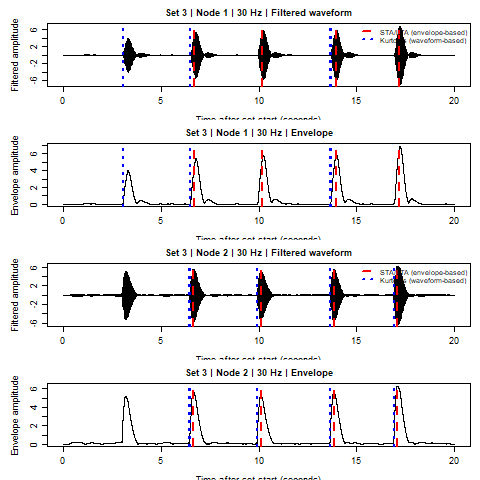

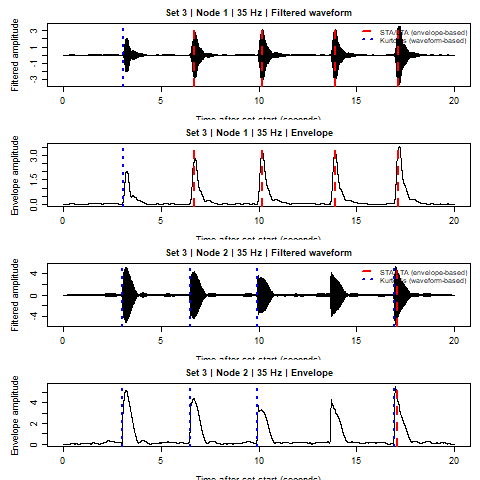

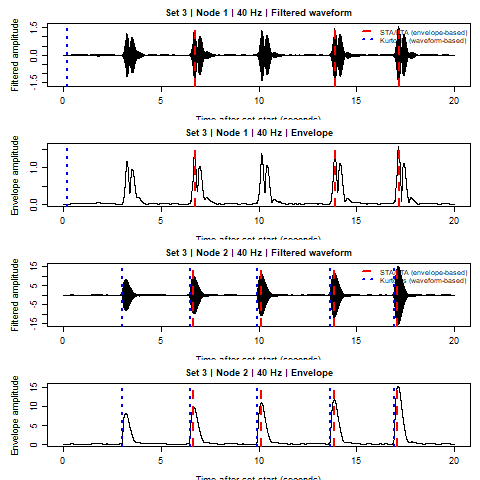

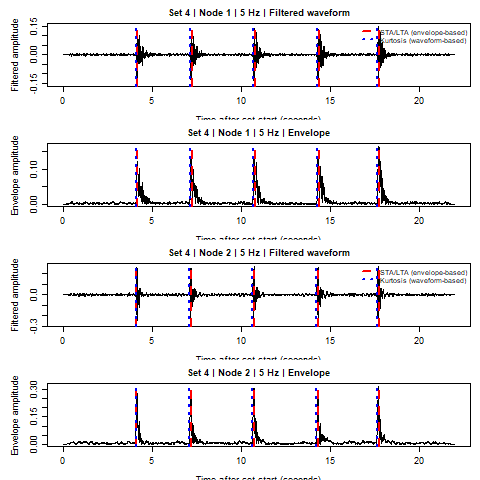

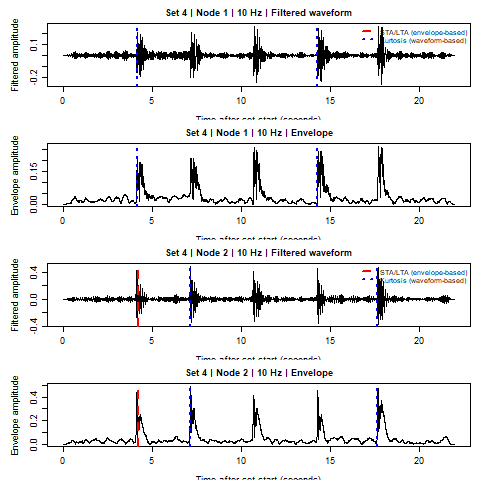

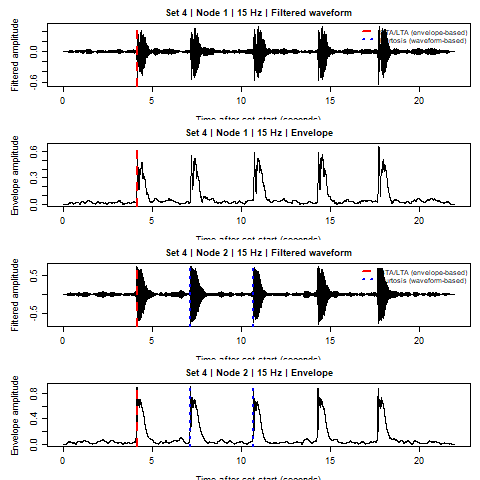

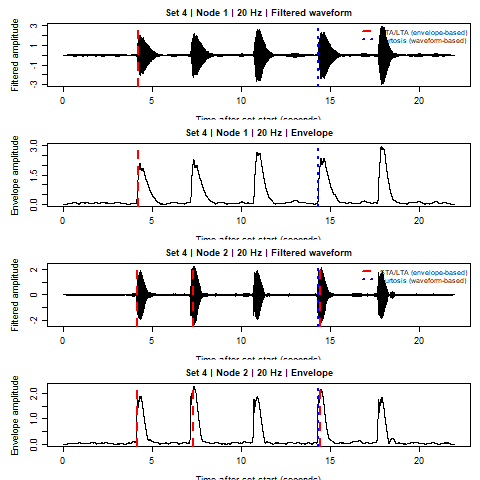

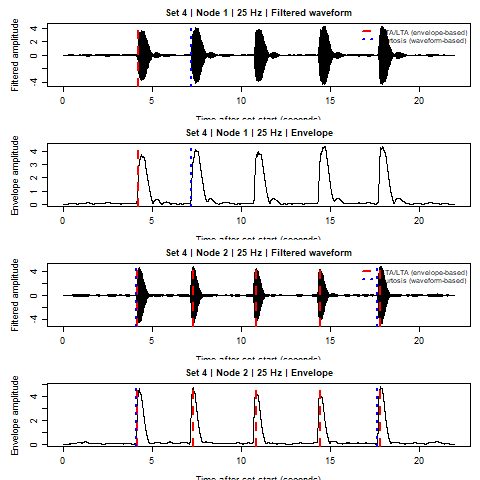

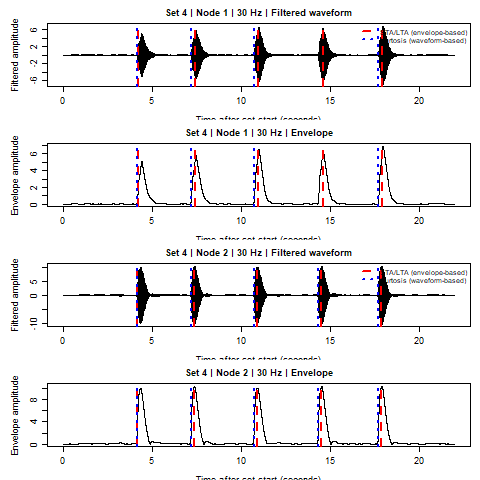

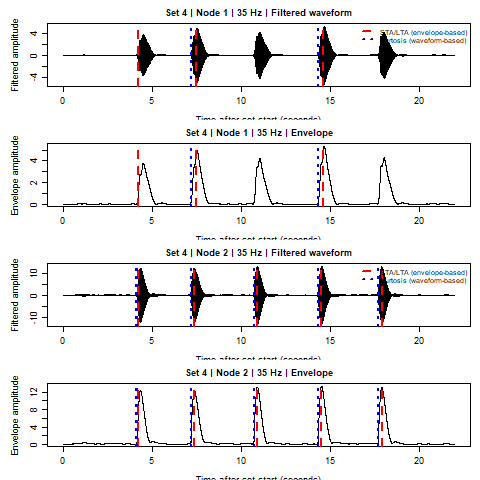

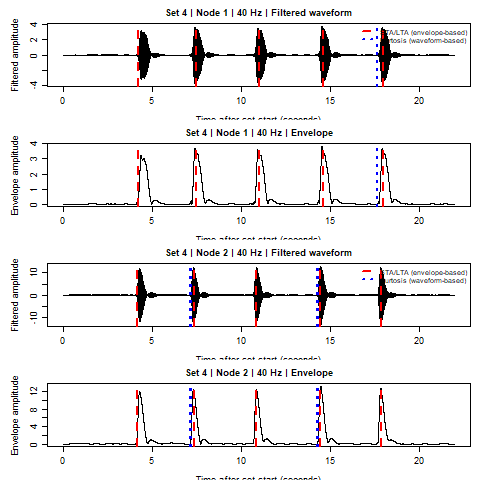

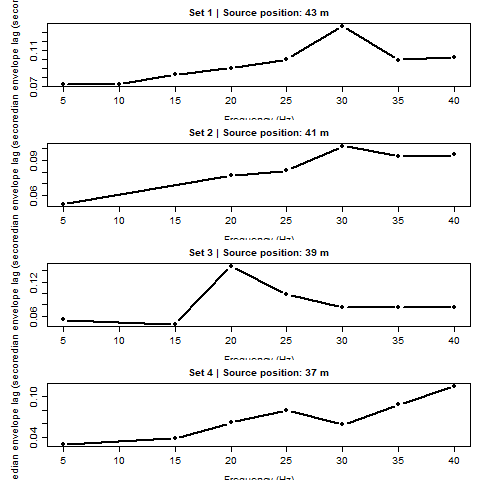

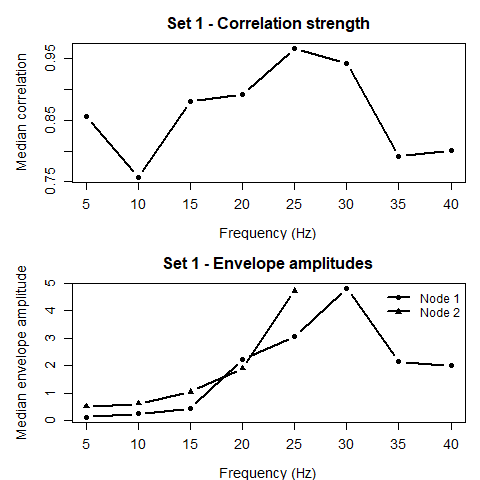

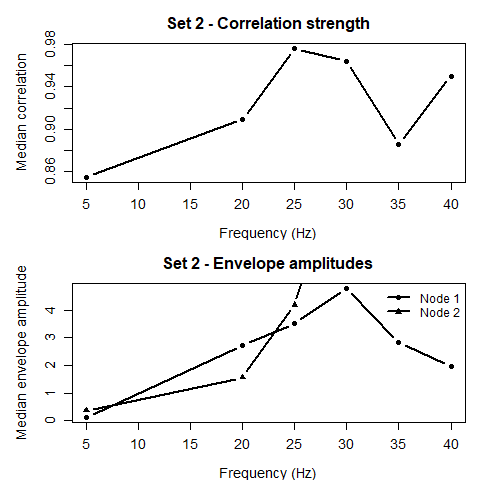

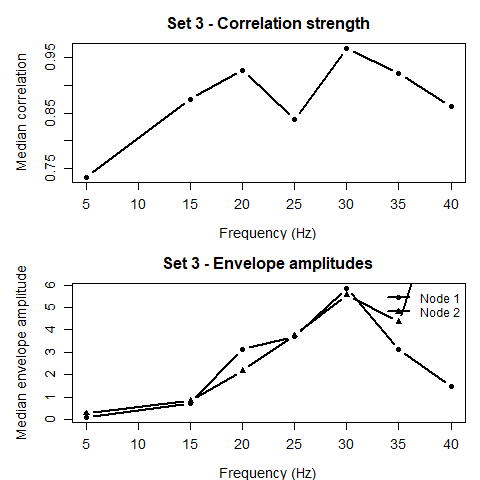

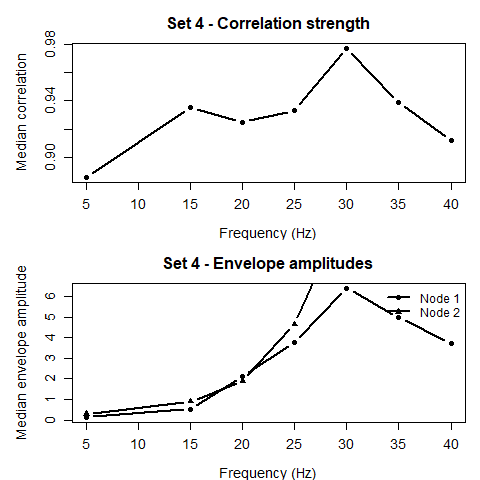

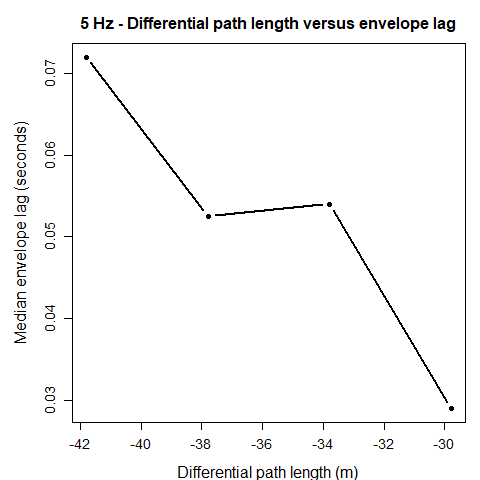

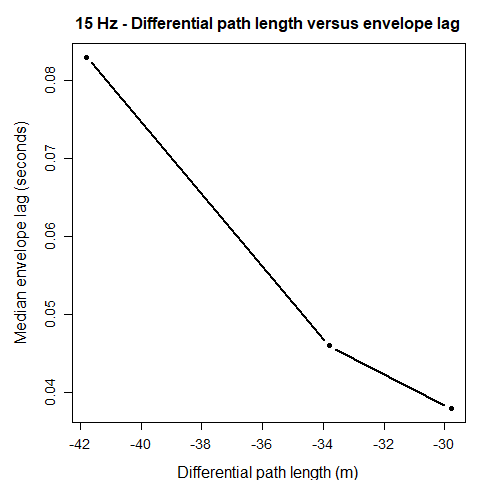

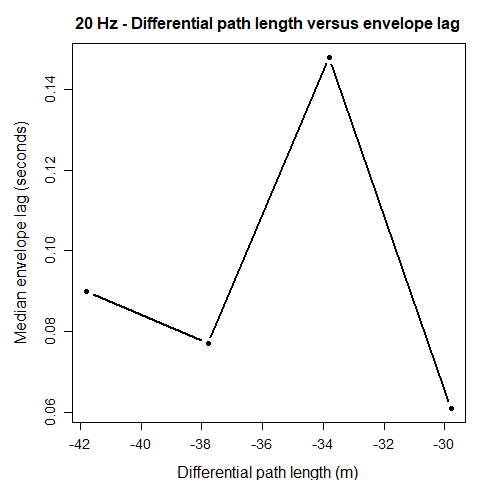

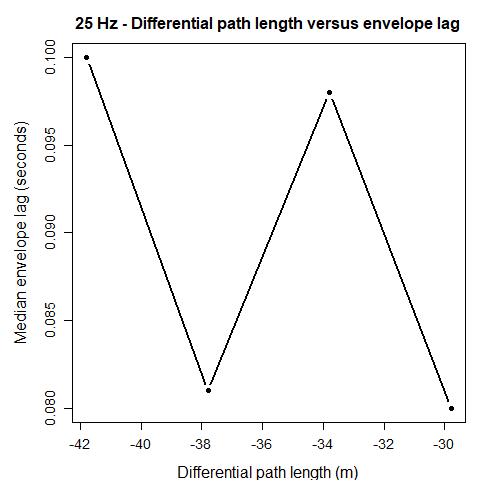

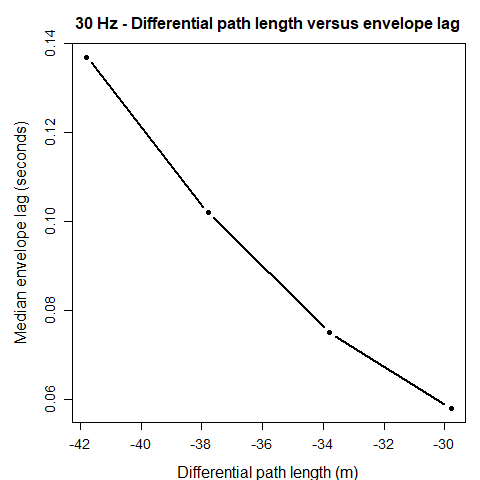

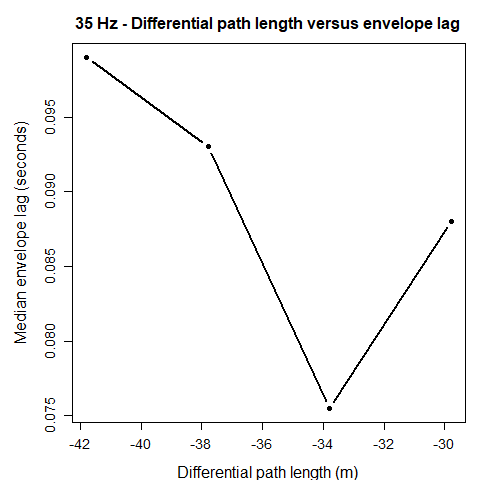

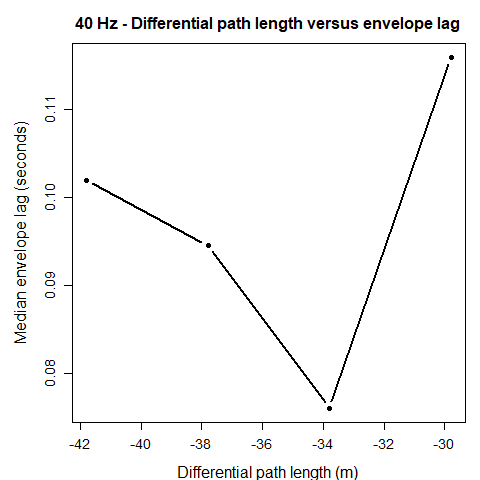

In [16]:
%%R
# PART 2: freq dependent picking and cross-correlation

# for each source strike location/set of impacts:
#   1. clip the original raw data to the hammer-test window
#   2. filter both sensors into each frequency band
#   3. calculate the envelope of each filtered signal
#   4. run STA/LTA and kurtosis picking separately for each frequency band and node
#   5. plot the filtered envelopes and picks
#   6. cross-correlate the two filtered envelopes around each node 1 STA/LTA pick

# results are retained separately for each frequency and event


# A. parameters

# frequency bandwidth: each center frequency is +/- 1 Hz
filter_half_width <- 1

# cross-correlation event window around the node 1 pick
# in seconds, not samples
# a longer window than the original 0.2 / 0.4 s gives the correlation more of the waveform/envelope to work with
# check that it doesn't include the next hammer impact
pre_buffer <- 0.5
post_buffer <- 1.5

# maximum lag to search, in samples
# 1000 samples = 1 second at 1000 Hz
lag_max <- 1000

# plot size
options(repr.plot.width = 15, repr.plot.height = 9)

# keep the sample interval from the actual data metadata
sample_dt <- s$a$meta$dt


# B. helper funciton: convert pick times to relative seconds
pick_seconds <- function(picks, reference_time) {

  if (is.null(picks) || nrow(picks) == 0) {
    return(numeric(0))
  }

  return(as.numeric(difftime(
    picks$start,
    reference_time,
    units = "secs"
  )))
}


# C. initialize result saving

# one entry per set and frequency
# each entry contains the filtered data, envelopes, and picks
frequency_results <- list()

# one row per set, frequency, and node 1 event for cross-correlation results.
xcorr_list <- list()

xcorr_counter <- 1


# D. loop through sets and frequencies
for (i in seq_len(nrow(blows))) {

  cat("\n-------------------------------------\n")
  cat("Processing set:", i, "\n")
  cat("Source position:", blows$x_m[i], "m from Node 1\n")
  cat("\n-------------------------------------\n")

  # clip the original full-freq data to this set's time window
  set_start <- blows$start[i]
  set_end <- set_start + blows$duration[i]

  s_blow <- signal_clip(
    data = s,
    limits = c(set_start, set_end)
  )

  # save the actual start time of the clipped record
  clip_start <- s_blow$a$meta$starttime

  # loop through the frequency bands
  for (j in seq_along(f)) {

    freq <- f[j]

    cat("\nFrequency:", freq, "Hz\n")

      
    # D1. filter both nodes
      
    # filtering is done BEFORE picking
    # both sensors use the same frequency band
    s_filtered <- signal_filter(
      data = s_blow,
      f = c(freq - filter_half_width,
            freq + filter_half_width),
      lazy = TRUE,
      p = 0.02
    )

    # D2. calculate envelopes

    # envelope is used for STA/LTA event detection
    e_filtered <- signal_envelope(
      data = s_filtered
    )

    # D3. run STA/LTA on each node 
    p_stalta_a <- pick_stalta(
      data = e_filtered$a,
      sta = sta,
      lta = lta,
      freeze = TRUE,
      on = stalta_on,
      off = stalta_off
    )

    p_stalta_b <- pick_stalta(
      data = e_filtered$b,
      sta = sta,
      lta = lta,
      freeze = TRUE,
      on = stalta_on,
      off = stalta_off
    )

    # D4. run kurtosis on each node

    # kurtosis is a separate picker, not an automatic refinement of the STA/LTA picks ---???
    
    # running it on the same frequency-filtered envelopes so that both picking methods examine the same band

    # p_kurt_a <- tryCatch(
    #   pick_kurtosis(
    #     data = e_filtered$a,
    #     window_kurt = kurt_window,
    #     on = kurt_on,
    #     off = kurt_off,
    #     dur_min = kurt_dur_min,
    #     dur_max = kurt_dur_max,
    #     window_amp = kurt_amp_window
    #   ),
    #   error = function(e) {
    #     message("Kurtosis failed for Node 1: ", e$message)
    #     NULL
    #   }
    # )

    # p_kurt_b <- tryCatch(
    #   pick_kurtosis(
    #     data = e_filtered$b,
    #     window_kurt = kurt_window,
    #     on = kurt_on,
    #     off = kurt_off,
    #     dur_min = kurt_dur_min,
    #     dur_max = kurt_dur_max,
    #     window_amp = kurt_amp_window
    #   ),
    #   error = function(e) {
    #     message("Kurtosis failed for Node 2: ", e$message)
    #     NULL
    #   }
    # )

    p_kurt_a <- tryCatch(
      pick_kurtosis(
        data = s_filtered$a,  # filtered waveform, not envelope
        window_kurt = kurt_window,
        on = kurt_on,
        off = kurt_off,
        dur_min = kurt_dur_min,
        dur_max = kurt_dur_max,
        window_amp = kurt_amp_window
      ),
      error = function(e) {
        message("Kurtosis failed for Node 1: ", e$message)
        NULL
      }
    )
    
    p_kurt_b <- tryCatch(
      pick_kurtosis(
        data = s_filtered$b,  # filtered waveform, not envelope
        window_kurt = kurt_window,
        on = kurt_on,
        off = kurt_off,
        dur_min = kurt_dur_min,
        dur_max = kurt_dur_max,
        window_amp = kurt_amp_window
      ),
      error = function(e) {
        message("Kurtosis failed for Node 2: ", e$message)
        NULL
      }
    )      

    # extract pick tables, allowing for a failed kurtosis run
    kurt_picks_a <- if (is.null(p_kurt_a)) {
      data.frame()
    } else {
      p_kurt_a$picks
    }

    kurt_picks_b <- if (is.null(p_kurt_b)) {
      data.frame()
    } else {
      p_kurt_b$picks
    }


    # D5. save all data and picks

    result_key <- paste0("set_", i, "_freq_", freq)

    frequency_results[[result_key]] <- list(
      set = i,
      frequency = freq,
      filtered = s_filtered,
      envelope = e_filtered,
      stalta_a = p_stalta_a$picks,
      stalta_b = p_stalta_b$picks,
      kurtosis_a = kurt_picks_a,
      kurtosis_b = kurt_picks_b
    )

    # print number of picks from each method
    cat("Node 1 STA/LTA:", nrow(p_stalta_a$picks), "\n")
    cat("Node 2 STA/LTA:", nrow(p_stalta_b$picks), "\n")
    cat("Node 1 kurtosis:", nrow(kurt_picks_a), "\n")
    cat("Node 2 kurtosis:", nrow(kurt_picks_b), "\n")



    # D6. plot frequency-specific waveforms, envelopes, and picks
    
    # use the actual filtered waveform time axes
    # both the waveform and envelope should have the same sample times
    
    time_a <- seq(
      from = 0,
      by = s_filtered$a$meta$dt,
      length.out = length(s_filtered$a$signal)
    )
    
    time_b <- seq(
      from = 0,
      by = s_filtered$b$meta$dt,
      length.out = length(s_filtered$b$signal)
    )
    
    # convert all pick times to seconds relative to the clipped set start
    stalta_times_a <- pick_seconds(p_stalta_a$picks, clip_start)
    stalta_times_b <- pick_seconds(p_stalta_b$picks, clip_start)
    
    kurt_times_a <- pick_seconds(kurt_picks_a, clip_start)
    kurt_times_b <- pick_seconds(kurt_picks_b, clip_start)
    
    # four panels:
    # 1. node 1 filtered waveform
    # 2. node 1 envelope
    # 3. node 2 filtered waveform
    # 4. node 2 envelope
    
    par(
      mfrow = c(4, 1),
      mar = c(3.5, 5, 2.5, 1),
      cex.axis = 1.1,
      cex.lab = 1.15
    )
    
    # NODE 1: FILTERED WAVEFORM
    plot(
      time_a,
      s_filtered$a$signal,
      type = "l",
      xlab = "Time after set start (seconds)",
      ylab = "Filtered amplitude",
      main = paste("Set", i, "| Node 1 |", freq, "Hz | Filtered waveform"),
      cex.main = 1.1
    )
    
    if (length(stalta_times_a) > 0) {
      abline(v = stalta_times_a, col = "red", lty = 2, lwd = 2)
    }
    
    if (length(kurt_times_a) > 0) {
      abline(v = kurt_times_a, col = "blue", lty = 3, lwd = 2)
    }
    
    legend(
      "topright",
      legend = c("STA/LTA (envelope-based)", "Kurtosis (waveform-based)"),
      col = c("red", "blue"),
      lty = c(2, 3),
      lwd = 2,
      cex = 0.85,
      bty = "n"
    )
    
    # NODE 1: ENVELOPE
    plot(
      time_a,
      e_filtered$a$signal,
      type = "l",
      xlab = "Time after set start (seconds)",
      ylab = "Envelope amplitude",
      main = paste("Set", i, "| Node 1 |", freq, "Hz | Envelope"),
      cex.main = 1.1
    )
    
    if (length(stalta_times_a) > 0) {
      abline(v = stalta_times_a, col = "red", lty = 2, lwd = 2)
    }
    
    if (length(kurt_times_a) > 0) {
      abline(v = kurt_times_a, col = "blue", lty = 3, lwd = 2)
    }
    
    # NODE 2: FILTERED WAVEFORM
    plot(
      time_b,
      s_filtered$b$signal,
      type = "l",
      xlab = "Time after set start (seconds)",
      ylab = "Filtered amplitude",
      main = paste("Set", i, "| Node 2 |", freq, "Hz | Filtered waveform"),
      cex.main = 1.1
    )
    
    if (length(stalta_times_b) > 0) {
      abline(v = stalta_times_b, col = "red", lty = 2, lwd = 2)
    }
    
    if (length(kurt_times_b) > 0) {
      abline(v = kurt_times_b, col = "blue", lty = 3, lwd = 2)
    }
    
    legend(
      "topright",
      legend = c("STA/LTA (envelope-based)", "Kurtosis (waveform-based)"),
      col = c("red", "blue"),
      lty = c(2, 3),
      lwd = 2,
      cex = 0.85,
      bty = "n"
    )
    
    # NODE 2: ENVELOPE
    plot(
      time_b,
      e_filtered$b$signal,
      type = "l",
      xlab = "Time after set start (seconds)",
      ylab = "Envelope amplitude",
      main = paste("Set", i, "| Node 2 |", freq, "Hz | Envelope"),
      cex.main = 1.1
    )
    
    if (length(stalta_times_b) > 0) {
      abline(v = stalta_times_b, col = "red", lty = 2, lwd = 2)
    }
    
    if (length(kurt_times_b) > 0) {
      abline(v = kurt_times_b, col = "blue", lty = 3, lwd = 2)
}

    # D6. plot frequency-specific picks

    # # time axis relative to the beginning of clipped set
    # time_a <- seq(
    #   from = 0,
    #   by = e_filtered$a$meta$dt,
    #   length.out = length(e_filtered$a$signal)
    # )

    # time_b <- seq(
    #   from = 0,
    #   by = e_filtered$b$meta$dt,
    #   length.out = length(e_filtered$b$signal)
    # )

    # # convert pick times to seconds relative to clip start
    # stalta_times_a <- pick_seconds(
    #   p_stalta_a$picks, clip_start
    # )

    # stalta_times_b <- pick_seconds(
    #   p_stalta_b$picks, clip_start
    # )

    # kurt_times_a <- pick_seconds(
    #   kurt_picks_a, clip_start
    # )

    # kurt_times_b <- pick_seconds(
    #   kurt_picks_b, clip_start
    # )

    # # two vertically stacked plots, one for each node
    # par(
    #   mfrow = c(2, 1),
    #   mar = c(4, 5, 3, 1),
    #   cex.axis = 1.1,
    #   cex.lab = 1.2
    # )

    # # node 1 - og node
    # plot(
    #   time_a,
    #   e_filtered$a$signal,
    #   type = "l",
    #   xlab = "Time after set start (seconds)",
    #   ylab = "Envelope amplitude",
    #   main = paste(
    #     "Set", i, "| Node 1 |", freq, "Hz"
    #   ),
    #   cex.main = 1.3
    # )

    # if (length(stalta_times_a) > 0) {
    #   abline(
    #     v = stalta_times_a,
    #     col = "red",
    #     lty = 2,
    #     lwd = 2
    #   )
    # }

    # if (length(kurt_times_a) > 0) {
    #   abline(
    #     v = kurt_times_a,
    #     col = "blue",
    #     lty = 3,
    #     lwd = 2
    #   )
    # }

    # legend(
    #   "topright",
    #   legend = c("STA/LTA", "Kurtosis"),
    #   col = c("red", "blue"),
    #   lty = c(2, 3),
    #   lwd = 2,
    #   bty = "n"
    # )

    # # node 2 - calib node
    # plot(
    #   time_b,
    #   e_filtered$b$signal,
    #   type = "l",
    #   xlab = "Time after set start (seconds)",
    #   ylab = "Envelope amplitude",
    #   main = paste(
    #     "Set", i, "| Node 2 |", freq, "Hz"
    #   ),
    #   cex.main = 1.3
    # )

    # if (length(stalta_times_b) > 0) {
    #   abline(
    #     v = stalta_times_b,
    #     col = "red",
    #     lty = 2,
    #     lwd = 2
    #   )
    # }

    # if (length(kurt_times_b) > 0) {
    #   abline(
    #     v = kurt_times_b,
    #     col = "blue",
    #     lty = 3,
    #     lwd = 2
    #   )
    # }

    # legend(
    #   "topright",
    #   legend = c("STA/LTA", "Kurtosis"),
    #   col = c("red", "blue"),
    #   lty = c(2, 3),
    #   lwd = 2,
    #   bty = "n"
    # )


    # D7. cross-correlate filtered envelopes

    # node 1 STA/LTA picks are used as event reference times
    # the same absolute-time window is extracted from BOTH nodes.
    # this avoids pairing independent pick numbers when one node misses an event

    # node 2 picks are retained separately for comparison

    event_picks <- p_stalta_a$picks

    if (is.null(event_picks) || nrow(event_picks) == 0) {
      cat("No Node 1 STA/LTA picks; skipping correlation.\n")
      next
    }

    for (k in seq_len(nrow(event_picks))) {

      event_time <- event_picks$start[k]

      # extract a window around the node 1 pick
      event_limits <- c(
        event_time - pre_buffer,
        event_time + post_buffer
      )

      event_filtered <- tryCatch(
        signal_clip(
          data = s_filtered,
          limits = event_limits
        ),
        error = function(e) NULL
      )

      if (is.null(event_filtered)) {
        next
      }

      # calculate envelopes for the event window
      event_envelope <- signal_envelope(
        data = event_filtered
      )

      x <- event_envelope$a$signal
      y <- event_envelope$b$signal

      # confirm equal lengths
      n <- min(length(x), length(y))

      if (n < 10) {
        next
      }

      x <- x[seq_len(n)]
      y <- y[seq_len(n)]

      # skip windows containing invalid values
      if (any(!is.finite(x)) || any(!is.finite(y))) {
        next
      }

      # sampling interval from actual clipped data
      sample_dt <- event_envelope$a$meta$dt

      # maximum lag cannot exceed the available signal length
      lag_limit <- min(lag_max, n - 2)

      # cross-correlation of the two filtered envelopes
      cc <- ccf(
        x = x,
        y = y,
        lag.max = lag_limit,
        plot = FALSE
      )

      # select lag with the strongest absolute correlation
      peak_index <- which.max(as.numeric(cc$acf)) # or peak_index <- which.max(abs(as.numeric(cc$acf))) ???

      peak_corr <- as.numeric(cc$acf)[peak_index]
      lag_samples <- as.numeric(cc$lag)[peak_index]

      # convert samples to seconds
      lag_seconds <- lag_samples * sample_dt

      # maximum envelope amplitude in each event window
      amplitude_a <- max(x, na.rm = TRUE)
      amplitude_b <- max(y, na.rm = TRUE)

      # store the result for this event and frequency
      xcorr_list[[xcorr_counter]] <- data.frame(
        set = i,
        source_x_m = blows$x_m[i],
        distance_N1_m = blows$dist_N1_m[i],
        distance_N2_m = blows$dist_N2_m[i],
        delta_r_m = blows$delta_r_m[i],
        event = k,
        event_time = as.character(event_time),
        frequency = freq,
        lag_samples = lag_samples,
        lag_seconds = lag_seconds,
        peak_correlation = peak_corr,
        amplitude_N1 = amplitude_a,
        amplitude_N2 = amplitude_b
      )

      xcorr_counter <- xcorr_counter + 1
    }
  }
}


# E. combine cross-correlation results

if (length(xcorr_list) > 0) {

  xcorr_results <- do.call(rbind, xcorr_list)
  rownames(xcorr_results) <- NULL

  cat("\nCross-correlation results:\n")
  print(xcorr_results)

} else {

  xcorr_results <- data.frame()
  cat("\nNo cross-correlation results were generated.\n")
}


# F. summarize results by set of blows and frequency

# median summarizes the five impacts at each location
# individual results remain in xcorr_results for inspection

if (nrow(xcorr_results) > 0) {

  summary_results <- aggregate(
    cbind(
      lag_seconds,
      peak_correlation,
      amplitude_N1,
      amplitude_N2
    ) ~ set + source_x_m + distance_N1_m +
        distance_N2_m + delta_r_m + frequency,
    data = xcorr_results,
    FUN = median,
    na.rm = TRUE
  )

  names(summary_results)[
    names(summary_results) == "lag_seconds"
  ] <- "median_lag_seconds"

  names(summary_results)[
    names(summary_results) == "peak_correlation"
  ] <- "median_correlation"

  names(summary_results)[
    names(summary_results) == "amplitude_N1"
  ] <- "median_amplitude_N1"

  names(summary_results)[
    names(summary_results) == "amplitude_N2"
  ] <- "median_amplitude_N2"

  cat("\nMedian results by set and frequency:\n")
  print(summary_results)

} else {

  summary_results <- data.frame()
}


# G. plot median lag vs frequency

if (nrow(summary_results) > 0) {

  options(repr.plot.width = 14, repr.plot.height = 8)

  for (i in unique(summary_results$set)) {

    d <- summary_results[
      summary_results$set == i, ]

    d <- d[order(d$frequency), ]

    plot(
      d$frequency,
      d$median_lag_seconds,
      type = "b",
      pch = 16,
      lwd = 2,
      xlab = "Frequency (Hz)",
      ylab = "Median envelope lag (seconds)",
      main = paste(
        "Set", i,
        "| Source position:", blows$x_m[i], "m"
      ),
      cex.axis = 1.2,
      cex.lab = 1.3,
      cex.main = 1.3
    )
  }
}


# H. plot correlation and amplitudes

if (nrow(summary_results) > 0) {

  options(repr.plot.width = 14, repr.plot.height = 9)

  for (i in unique(summary_results$set)) {

    d <- summary_results[
      summary_results$set == i, ]

    d <- d[order(d$frequency), ]

    par(
      mfrow = c(2, 1),
      mar = c(4, 5, 3, 1)
    )

    # median correlation by frequency
    plot(
      d$frequency,
      d$median_correlation,
      type = "b",
      pch = 16,
      lwd = 2,
      xlab = "Frequency (Hz)",
      ylab = "Median correlation",
      main = paste("Set", i, "- Correlation strength"),
      cex.axis = 1.2,
      cex.lab = 1.2,
      cex.main = 1.3
    )

    # median amplitudes by frequency
    plot(
      d$frequency,
      d$median_amplitude_N1,
      type = "b",
      pch = 16,
      lwd = 2,
      xlab = "Frequency (Hz)",
      ylab = "Median envelope amplitude",
      main = paste("Set", i, "- Envelope amplitudes"),
      cex.axis = 1.2,
      cex.lab = 1.2,
      cex.main = 1.3
    )

    lines(
      d$frequency,
      d$median_amplitude_N2,
      type = "b",
      pch = 17,
      lwd = 2
    )

    legend(
      "topright",
      legend = c("Node 1", "Node 2"),
      pch = c(16, 17),
      lty = 1,
      lwd = 2,
      bty = "n"
    )
  }
}

# reset plotting layout
par(mfrow = c(1, 1))


# I. plot lag against differential path length

# only a preliminary comparison
# the lags are envelope cross-correlation delays, not yet verified first-arrival travel times

if (nrow(summary_results) > 0) {

  options(repr.plot.width = 14, repr.plot.height = 8)

  for (freq in f) {

    d <- summary_results[
      summary_results$frequency == freq, ]

    d <- d[order(d$delta_r_m), ]

    if (nrow(d) < 2) {
      next
    }

    plot(
      d$delta_r_m,
      d$median_lag_seconds,
      type = "b",
      pch = 16,
      lwd = 2,
      xlab = "Differential path length (m)",
      ylab = "Median envelope lag (seconds)",
      main = paste(
        freq,
        "Hz - Differential path length versus envelope lag"
      ),
      cex.axis = 1.2,
      cex.lab = 1.3,
      cex.main = 1.3
    )
  }
}

In [ ]:
%%R
# Check the two original seismic records

for (nm in names(s)) {

  cat("\n-------------------------\n")
  cat("Sensor:", nm, "\n")

  cat("Class:", class(s[[nm]])[1], "\n")

  cat("Sampling interval (dt):",
      s[[nm]]$meta$dt, "\n")

  cat("Sampling rate:",
      1 / s[[nm]]$meta$dt, "\n")

  cat("Number of samples:",
      s[[nm]]$meta$n, "\n")

  cat("Start time:",
      as.character(s[[nm]]$meta$starttime), "\n")

  cat("End time:",
      as.character(
        s[[nm]]$meta$starttime +
          (s[[nm]]$meta$n - 1) * s[[nm]]$meta$dt
      ), "\n")

  cat("Signal length:",
      length(s[[nm]]$signal), "\n")

  cat("Missing signal values:",
      sum(is.na(s[[nm]]$signal)), "\n")
}


# Compare requested clipping windows with record times

for (i in seq_len(nrow(blows))) {

  requested_start <- blows$start[i]
  requested_end <- blows$start[i] + blows$duration[i]

  cat("\nSet:", i, "\n")
  cat("Requested start:", as.character(requested_start), "\n")
  cat("Requested end:", as.character(requested_end), "\n")

  for (nm in names(s)) {

    actual_start <- s[[nm]]$meta$starttime

    actual_end <- actual_start +
      (s[[nm]]$meta$n - 1) * s[[nm]]$meta$dt

    cat(
      nm,
      "| Record start:", as.character(actual_start),
      "| Record end:", as.character(actual_end),
      "\n"
    )

    cat(
      "Requested window inside record:",
      requested_start >= actual_start &&
        requested_end <= actual_end,
      "\n"
    )
  }
}

warnings()


In [ ]:
# corrections
Correction 1: Sampling interval variable

In Part A, use:
sample_dt <- 1 / fs


In Part C, replace:
dt <- rep(NA_real_, n_events)


with:
dt_lag <- rep(NA_real_, n_events)


Then replace:
dt[k] <- cc$lag[idx] * dt


with:
dt_lag[k] <- cc$lag[idx] * sample_dt


And in the output table, replace:
dt_crosscorr_s = dt


with:
dt_crosscorr_s = dt_lag


This avoids overwriting the sampling interval.

    Correction 2: Remove this redundant line in Part D:
summary_results$dist_N1_m <-
  L - summary_results$source_x_m


The correct assignment is the following line:
summary_results$dist_N1_m <-
  summary_results$source_x_m


Correction 3: Don't assume the fifth kurtosis pick is necessarily the fifth hammer strike at both nodes.

The script matches Node 1 and Node 2 picks by their order in the tables. This is only a provisional matching strategy. If one node misses a strike, the subsequent picks could become misaligned.

Before using dt_first_arrival_s as a scientific result, you need to verify that the corresponding picks represent the same hammer strike. Your approximate field-note times can help establish that correspondence.

In [ ]:
%%R



# There is one correction needed in that code before running it: the variable dt is also used for the sampling interval at the top.
# To avoid overwriting it with the output vector, change the sampling-interval variable at the top to sample_dt <- 1/fs, and change the cross-correlation assignment to:
#     dt[k] <- cc$lag[idx] * sample_dt

### AI SUGGESTIONS
## untested

# select which picks to use for event windows

# options: "kurtosis" or "stalta"
pick_method <- "kurtosis"

# initialize output
all_results <- list()

# process by freq dependence
for (i in seq_along(results)) {

  cat("\nFrequency processing: set", i, "\n")

  s_blow <- results[[i]]$waveform

  # select event picks from node 1
  if (pick_method == "kurtosis") {

    event_picks <- results[[i]]$kurtosis_A

  } else {

    event_picks <- results[[i]]$stalta_A
  }

  # independent node 2 picks for comparison
  picks_B <- if (pick_method == "kurtosis") {
    results[[i]]$kurtosis_B
  } else {
    results[[i]]$stalta_B
  }

  n_events <- nrow(event_picks)

  cat("Detected events:", n_events, "\n")

  # output tables for this strike location
  set_output <- list()

  # process each freq
  for (j in seq_along(f)) {

    cat("Frequency:", f[j], "Hz\n")

    # narrow bandpass filtering around each center frequency
    s_f <- signal_filter(
      data = s_blow,
      f = c(f[j] - 1, f[j] + 1),
      lazy = TRUE,
      p = 0.02
    )

    # individual event results
    dt <- rep(NA_real_, n_events)
    corr <- rep(NA_real_, n_events)

    amp_A <- rep(NA_real_, n_events)
    amp_B <- rep(NA_real_, n_events)

    arrival_A <- event_picks$start
    arrival_B <- rep(as.POSIXct(NA, tz = "UTC"), n_events)

    dt_pick <- rep(NA_real_, n_events)

    # process each individual hammer strike
    for (k in seq_len(n_events)) {

      # candidate event onset from node 1
      event_start <- event_picks$start[k]

      # event duration
      event_duration <- event_picks$duration[k]

      # if duration is unavailable, use a fixed window
      if (is.na(event_duration) ||
          !is.finite(event_duration)) {
        event_duration <- 1
      }

      # independent arrival pick at node 2
      if (k <= nrow(picks_B)) {

        arrival_B[k] <- picks_B$start[k]

        dt_pick[k] <- as.numeric(
          difftime(
            arrival_B[k],
            arrival_A[k],
            units = "secs"
          )
        )
      }

      # clip individual event
      e_k <- signal_clip(
        data = s_f,
        limits = c(
          event_start - pre_buffer,
          event_start + event_duration + post_buffer
        )
      )

      # calculate envelopes
      e_k <- signal_envelope(data = e_k)

      # max envelope amplitudes
      # Added from supervisor's recommendation.
      # Retained separately for both sensors.

      amp_A[k] <- max(
        e_k$a$signal,
        na.rm = TRUE
      )

      amp_B[k] <- max(
        e_k$b$signal,
        na.rm = TRUE
      )

      # ---------------------------------------------------
      # CROSS-CORRELATION
      # ---------------------------------------------------

      cc <- ccf(
        x = e_k$a$signal,
        y = e_k$b$signal,
        lag.max = lag_max,
        plot = FALSE
      )

      # Find the largest absolute correlation coefficient
      idx <- which.max(abs(cc$acf))

      # Time lag in seconds
      dt[k] <- cc$lag[idx] * dt

      # Correlation coefficient at selected lag
      corr[k] <- cc$acf[idx]

      # ---------------------------------------------------
      # OPTIONAL INDIVIDUAL EVENT PLOT
      # ---------------------------------------------------

      if (show_individual_plots && j == 1) {

        par(mfrow = c(2, 1))

        plot(
          e_k$a,
          main = paste(
            "Set", i,
            "Event", k,
            "Node 1"
          )
        )

        plot(
          e_k$b,
          main = paste(
            "Set", i,
            "Event", k,
            "Node 2"
          )
        )

        par(mfrow = c(1, 1))
      }
    }

    # -----------------------------------------------------
    # SAVE FREQUENCY RESULTS
    # -----------------------------------------------------

    set_output[[j]] <- data.frame(

      set = i,

      source_x_m = blows$x_m[i],

      frequency_Hz = f[j],

      event = seq_len(n_events),

      arrival_A = arrival_A,

      arrival_B = arrival_B,

      dt_first_arrival_s = dt_pick,

      dt_crosscorr_s = dt,

      correlation = corr,

      amplitude_A = amp_A,

      amplitude_B = amp_B
    )
  }

  all_results[[i]] <- do.call(
    rbind,
    set_output
  )
}

# Combine all sets and frequencies
results_all <- do.call(
  rbind,
  all_results
)

# View individual event results
print(results_all)


    
# ---------------------------------------------------------
# 10. CALCULATE MEDIAN VALUES BY SOURCE LOCATION/FREQUENCY
# ---------------------------------------------------------

summary_results <- aggregate(

  cbind(
    dt_first_arrival_s,
    dt_crosscorr_s,
    correlation,
    amplitude_A,
    amplitude_B
  ) ~ set + source_x_m + frequency_Hz,

  data = results_all,

  FUN = function(x) {
    median(x, na.rm = TRUE)
  }
)

# ---------------------------------------------------------
# 11. ADD GEOMETRY
# ---------------------------------------------------------

summary_results$dist_N1_m <-
  L - summary_results$source_x_m

summary_results$dist_N1_m <-
  summary_results$source_x_m

summary_results$dist_N2_m <-
  L - summary_results$source_x_m

summary_results$delta_r_m <-
  summary_results$dist_N2_m -
  summary_results$dist_N1_m

# ---------------------------------------------------------
# 12. CALCULATE APPARENT VELOCITIES
# ---------------------------------------------------------

# P-wave / first-arrival estimate
summary_results$v_first_arrival_m_s <-
  abs(summary_results$delta_r_m) /
  abs(summary_results$dt_first_arrival_s)

# Envelope cross-correlation estimate
summary_results$v_envelope_m_s <-
  abs(summary_results$delta_r_m) /
  abs(summary_results$dt_crosscorr_s)

# Remove infinite values and invalid midpoint estimates
summary_results$v_first_arrival_m_s[
  !is.finite(summary_results$v_first_arrival_m_s) |
    summary_results$delta_r_m == 0
] <- NA

summary_results$v_envelope_m_s[
  !is.finite(summary_results$v_envelope_m_s) |
    summary_results$delta_r_m == 0
] <- NA

print(summary_results)


          
# ---------------------------------------------------------
# 13. PLOT TIME DELAY VS FREQUENCY
# ---------------------------------------------------------

for (i in unique(results_all$set)) {

  dat <- results_all[
    results_all$set == i,
  ]

  med <- summary_results[
    summary_results$set == i,
  ]

  plot(
    dat$frequency_Hz,
    dat$dt_crosscorr_s * 1000,
    pch = 16,
    col = "gray50",
    xlab = "Frequency (Hz)",
    ylab = "Time lag (ms)",
    main = paste("Set", i, "- Individual time delays")
  )

  lines(
    med$frequency_Hz,
    med$dt_crosscorr_s * 1000,
    type = "b",
    lwd = 2,
    col = "blue"
  )
}

# ---------------------------------------------------------
# 14. PLOT FIRST-ARRIVAL VS CROSS-CORRELATION DELAYS
# ---------------------------------------------------------

for (i in unique(summary_results$set)) {

  dat <- summary_results[
    summary_results$set == i,
  ]

  plot(
    dat$frequency_Hz,
    dat$dt_crosscorr_s * 1000,
    type = "b",
    pch = 16,
    xlab = "Frequency (Hz)",
    ylab = "Time delay (ms)",
    main = paste("Set", i, "- Arrival vs envelope delay")
  )

  lines(
    dat$frequency_Hz,
    dat$dt_first_arrival_s * 1000,
    type = "b",
    pch = 17,
    col = "red"
  )

  legend(
    "topright",
    legend = c(
      "Envelope cross-correlation",
      "Independent arrival picks"
    ),
    col = c("black", "red"),
    pch = c(16, 17),
    lty = 1
  )
}

# ---------------------------------------------------------
# 15. PLOT AMPLITUDE VS FREQUENCY
# ---------------------------------------------------------

for (i in unique(summary_results$set)) {

  dat <- summary_results[
    summary_results$set == i,
  ]

  plot(
    dat$frequency_Hz,
    dat$amplitude_A,
    type = "b",
    pch = 16,
    xlab = "Frequency (Hz)",
    ylab = "Maximum envelope amplitude",
    main = paste("Set", i, "- Signal amplitude")
  )

  lines(
    dat$frequency_Hz,
    dat$amplitude_B,
    type = "b",
    pch = 17,
    col = "red"
  )

  legend(
    "topright",
    legend = c("Node 1", "Node 2"),
    col = c("black", "red"),
    pch = c(16, 17),
    lty = 1
  )
}

# ---------------------------------------------------------
# 16. PLOT CORRELATION COEFFICIENT VS FREQUENCY
# ---------------------------------------------------------

for (i in unique(results_all$set)) {

  dat <- results_all[
    results_all$set == i,
  ]

  plot(
    dat$frequency_Hz,
    dat$correlation,
    pch = 16,
    xlab = "Frequency (Hz)",
    ylab = "Maximum correlation coefficient",
    main = paste("Set", i, "- Correlation quality")
  )

  abline(h = 0, lty = 2)
}

# ---------------------------------------------------------
# 17. PLOT TIME DELAY VS SOURCE POSITION
# ---------------------------------------------------------

plot(
  summary_results$source_x_m,
  summary_results$dt_crosscorr_s * 1000,
  xlab = "Source position from Node 1 (m)",
  ylab = "Median envelope time delay (ms)",
  main = "Time delay vs source position",
  pch = 16
)

# ---------------------------------------------------------
# 18. PLOT APPARENT VELOCITY VS SOURCE POSITION
# ---------------------------------------------------------

plot(
  summary_results$source_x_m,
  summary_results$v_envelope_m_s,
  xlab = "Source position from Node 1 (m)",
  ylab = "Apparent envelope velocity (m/s)",
  main = "Apparent velocity vs source position",
  pch = 16
)
